In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/accepted_36m.parquet")
print(df.shape)

# Share of missing values per column
missing = df.isna().mean().sort_values(ascending=False)
missing[missing > 0]

(1023206, 26)


emp_length              0.064728
mort_acc                0.036707
pub_rec_bankruptcies    0.001334
revol_util              0.000711
dti                     0.000226
inq_last_6mths          0.000028
open_acc                0.000028
earliest_cr_line        0.000028
delinq_2yrs             0.000028
total_acc               0.000028
pub_rec                 0.000028
annual_inc              0.000004
dtype: float64

In [9]:
# Employment length: text -> number of years
emp_map = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4,
           "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9,
           "10+ years": 10}
df["emp_length_num"] = df["emp_length"].map(emp_map)

# Credit history length in years, measured at loan issue date
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")
df["credit_history_yrs"] = (df["issue_d"] - df["earliest_cr_line"]).dt.days / 365.25

# Average FICO score from the low/high range
df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2

# Drop the few near-empty rows (missing core fields)
df = df.dropna(subset=["annual_inc", "credit_history_yrs"])

# Impossible values -> NaN; the binning step puts NaN into its own "missing" bin
df.loc[df["annual_inc"] <= 0, "annual_inc"] = np.nan
df.loc[(df["dti"] < 0) | (df["dti"] > 100), "dti"] = np.nan
df.loc[df["revol_util"] > 150, "revol_util"] = np.nan

# Loan-to-income ratio (computed after cleaning income)
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]

# Remove original columns replaced by engineered features
df = df.drop(columns=["emp_length", "earliest_cr_line",
                      "fico_range_low", "fico_range_high", "loan_status"])
df.shape

(1023177, 25)

In [10]:
# Sanity check on distributions and outliers after cleaning
df[["annual_inc", "dti", "revol_util", "loan_to_income", "credit_history_yrs"]].describe(
    percentiles=[.01, .5, .99]).round(2)

,annual_inc,dti,revol_util,loan_to_income,credit_history_yrs
count,1022956.00,1022634.00,1022461.00,1022956.00,1023177.00
mean,74284.70,17.83,50.93,0.33,16.10
std,70741.15,8.64,24.52,56.13,7.64
min,1.00,0.00,0.00,0.00,0.50
1%,17000.00,1.68,1.00,0.02,3.75
50%,62000.00,17.22,51.00,0.17,14.58
99%,255000.00,38.12,98.10,0.49,40.00
max,10999200.00,100.00,146.10,35000.00,83.25


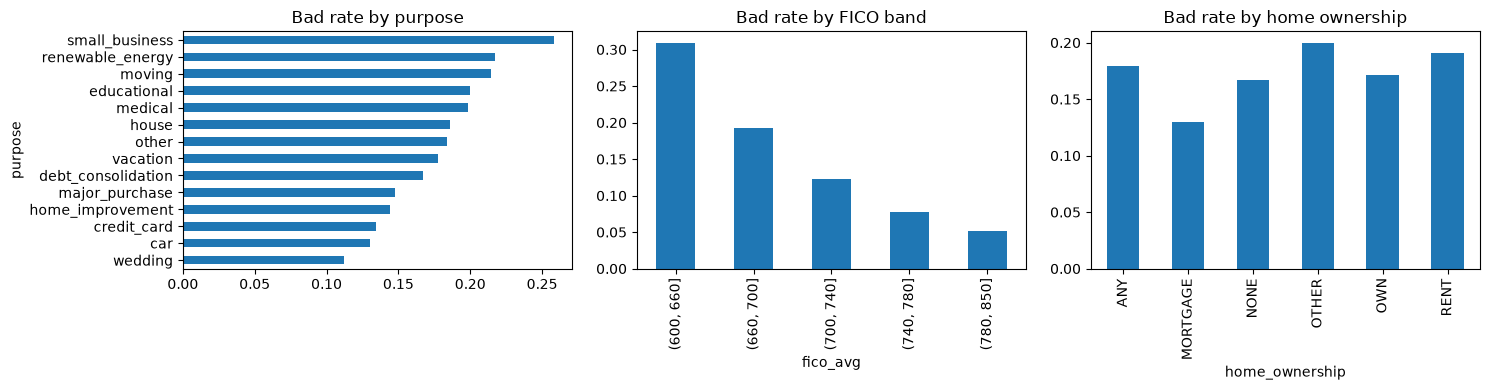

In [11]:
# Bad rate by key variables (figure saved for the README)
os.makedirs("../reports/figures", exist_ok=True)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby("purpose", observed=True)["target"].mean().sort_values().plot.barh(
    ax=ax[0], title="Bad rate by purpose")
df.groupby(pd.cut(df["fico_avg"], [600, 660, 700, 740, 780, 850]), observed=True)["target"].mean().plot.bar(
    ax=ax[1], title="Bad rate by FICO band")
df.groupby("home_ownership", observed=True)["target"].mean().plot.bar(
    ax=ax[2], title="Bad rate by home ownership")
plt.tight_layout()
plt.savefig("../reports/figures/eda_bad_rate.png", dpi=150)
plt.show()

In [12]:
# Save the cleaned dataset for the modelling notebooks
df.to_parquet("../data/processed/accepted_clean.parquet")